In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not os.path.exists('/content/analisis-logistica-banano'):
    !git clone https://github.com/D4veDurango/analisis-logistica-banano.git

os.chdir('/content/analisis-logistica-banano')

df = pd.read_csv('logistica_banano_uraba.csv')

print("Datos cargados correctamente")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

df.head()

Cloning into 'analisis-logistica-banano'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 51 (delta 26), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 137.41 KiB | 4.04 MiB/s, done.
Resolving deltas: 100% (26/26), done.
Datos cargados correctamente
Filas: 1500
Columnas: 11


,id_viaje,fecha_envio,municipio_origen,finca_origen,empresa_transporte,turno,horas_transito,cajas_enviadas,cajas_aprobadas,cajas_rechazadas,motivo_rechazo_principal
0,V-10000,2025-02-12,Apartadó,La Bonita Apartadó,Rutas del Darién,Mañana (4am-12pm),2.7,976,958,18,Cicatriz/Mancha
1,V-10001,2025-02-12,Chigorodó,El Bananal Chigorodó,Logística Bananera,Noche (8pm-4am),4.8,901,845,56,Calibre No Conforme
2,V-10002,2025-05-17,Chigorodó,El Bananal Chigorodó,Carga Agrícola S.A.,Mañana (4am-12pm),2.6,926,911,15,Daño Mecánico
3,V-10003,2025-01-06,Carepa,San José Carepa,Carga Agrícola S.A.,Tarde (12pm-8pm),2.4,987,938,49,Daño Mecánico
4,V-10004,2025-02-13,Chigorodó,El Tesoro Chigorodó,Logística Bananera,Mañana (4am-12pm),3.1,1046,1023,23,Madurez Prematura


In [2]:
# Cargar el archivo original
df = pd.read_csv('logistica_banano_uraba.csv')

# Conservar una copia de los datos originales
df_original = df.copy()

print("Datos cargados correctamente.")
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

display(df.head())

Datos cargados correctamente.
Cantidad de registros: 1500
Cantidad de columnas: 11


,id_viaje,fecha_envio,municipio_origen,finca_origen,empresa_transporte,turno,horas_transito,cajas_enviadas,cajas_aprobadas,cajas_rechazadas,motivo_rechazo_principal
0,V-10000,2025-02-12,Apartadó,La Bonita Apartadó,Rutas del Darién,Mañana (4am-12pm),2.7,976,958,18,Cicatriz/Mancha
1,V-10001,2025-02-12,Chigorodó,El Bananal Chigorodó,Logística Bananera,Noche (8pm-4am),4.8,901,845,56,Calibre No Conforme
2,V-10002,2025-05-17,Chigorodó,El Bananal Chigorodó,Carga Agrícola S.A.,Mañana (4am-12pm),2.6,926,911,15,Daño Mecánico
3,V-10003,2025-01-06,Carepa,San José Carepa,Carga Agrícola S.A.,Tarde (12pm-8pm),2.4,987,938,49,Daño Mecánico
4,V-10004,2025-02-13,Chigorodó,El Tesoro Chigorodó,Logística Bananera,Mañana (4am-12pm),3.1,1046,1023,23,Madurez Prematura


In [3]:
# Revisar los tipos de datos y la información general
print("Información general:")
df.info()

# Consultar las dimensiones del conjunto de datos
print("\nDimensiones:")
print(df.shape)

# Revisar las estadísticas de las variables numéricas
print("\nEstadísticas descriptivas:")
display(df.describe())

# Revisar los valores registrados en las columnas principales
print("\nMunicipios:")
print(df['municipio_origen'].value_counts())

print("\nTurnos:")
print(df['turno'].value_counts())

print("\nMotivos de rechazo:")
print(df['motivo_rechazo_principal'].value_counts())

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_viaje                  1500 non-null   object 
 1   fecha_envio               1500 non-null   object 
 2   municipio_origen          1500 non-null   object 
 3   finca_origen              1500 non-null   object 
 4   empresa_transporte        1500 non-null   object 
 5   turno                     1500 non-null   object 
 6   horas_transito            1455 non-null   float64
 7   cajas_enviadas            1500 non-null   int64  
 8   cajas_aprobadas           1500 non-null   int64  
 9   cajas_rechazadas          1500 non-null   int64  
 10  motivo_rechazo_principal  1500 non-null   object 
dtypes: float64(1), int64(3), object(7)
memory usage: 129.0+ KB

Dimensiones:
(1500, 11)

Estadísticas descriptivas:


,horas_transito,cajas_enviadas,cajas_aprobadas,cajas_rechazadas
count,1455.000000,1500.000000,1500.000000,1500.000000
mean,3.242955,947.433333,900.814667,46.618667
std,1.453868,86.464877,87.009828,27.067724
min,1.000000,800.000000,714.000000,8.000000
25%,2.050000,875.000000,826.750000,24.000000
50%,2.900000,945.000000,898.500000,42.000000
75%,4.400000,1024.000000,969.000000,65.000000
max,6.500000,1100.000000,1089.000000,128.000000



Municipios:
municipio_origen
Apartadó     381
Turbo        380
Chigorodó    378
Carepa       331
Chigorodo      9
carepa         9
Apartado       8
TURBO          4
Name: count, dtype: int64

Turnos:
turno
Noche (8pm-4am)      538
Mañana (4am-12pm)    490
Tarde (12pm-8pm)     472
Name: count, dtype: int64

Motivos de rechazo:
motivo_rechazo_principal
Madurez Prematura      513
Cicatriz/Mancha        340
Daño Mecánico          332
Calibre No Conforme    315
Name: count, dtype: int64


In [4]:
# Identificar valores faltantes en cada columna
print("Valores faltantes:")
display(df.isnull().sum().to_frame(name='valores_faltantes'))

# Revisar registros duplicados
print("\nFilas duplicadas:")
print(df.duplicated().sum())

# Revisar identificadores repetidos
print("\nIdentificadores duplicados:")
print(df['id_viaje'].duplicated().sum())

# Consultar los registros con horas de tránsito faltantes
print("\nRegistros sin horas de tránsito:")
display(df[df['horas_transito'].isnull()].head())

Valores faltantes:


,valores_faltantes
id_viaje,0
fecha_envio,0
municipio_origen,0
finca_origen,0
empresa_transporte,0
turno,0
horas_transito,45
cajas_enviadas,0
cajas_aprobadas,0
cajas_rechazadas,0



Filas duplicadas:
0

Identificadores duplicados:
0

Registros sin horas de tránsito:


,id_viaje,fecha_envio,municipio_origen,finca_origen,empresa_transporte,turno,horas_transito,cajas_enviadas,cajas_aprobadas,cajas_rechazadas,motivo_rechazo_principal
51,V-10051,2025-02-04,Apartadó,La Esperanza Apartadó,Carga Agrícola S.A.,Tarde (12pm-8pm),NaN,1021,972,49,Calibre No Conforme
70,V-10070,2025-02-03,Turbo,Villa Verde Turbo,Logística Bananera,Noche (8pm-4am),NaN,914,845,69,Calibre No Conforme
76,V-10076,2025-05-17,Carepa,La Esperanza Carepa,Rutas del Darién,Noche (8pm-4am),NaN,897,873,24,Daño Mecánico
220,V-10220,2025-06-13,Chigorodó,El Bananal Chigorodó,Carga Agrícola S.A.,Tarde (12pm-8pm),NaN,953,889,64,Cicatriz/Mancha
259,V-10259,2025-03-27,Carepa,El Bananal Carepa,TransUrabá,Noche (8pm-4am),NaN,832,819,13,Daño Mecánico


In [5]:
# Corregir espacios y diferencias de escritura en los municipios
df['municipio_origen'] = (
    df['municipio_origen']
    .str.strip()
    .str.title()
)

# Unificar los nombres que tenían errores tipográficos
df['municipio_origen'] = df['municipio_origen'].replace({
    'Apartado': 'Apartadó',
    'Chigorodo': 'Chigorodó'
})

# Convertir la fecha de envío al formato de fecha
df['fecha_envio'] = pd.to_datetime(
    df['fecha_envio'],
    errors='coerce'
)

print("Limpieza de municipios y fechas completada.")

print("\nMunicipios después de la limpieza:")
print(df['municipio_origen'].value_counts())

print("\nFechas no reconocidas:")
print(df['fecha_envio'].isnull().sum())

Limpieza de municipios y fechas completada.

Municipios después de la limpieza:
municipio_origen
Apartadó     389
Chigorodó    387
Turbo        384
Carepa       340
Name: count, dtype: int64

Fechas no reconocidas:
0


In [6]:
# Comprobar que las cajas enviadas correspondan a las aprobadas y rechazadas
df['diferencia_cajas'] = (
    df['cajas_enviadas']
    - df['cajas_aprobadas']
    - df['cajas_rechazadas']
)

# Identificar registros que no cumplen la relación
inconsistencias = df[df['diferencia_cajas'] != 0]

print(f"Registros con inconsistencias: {len(inconsistencias)}")

# Mostrar los registros inconsistentes, si existen
if len(inconsistencias) > 0:
    display(inconsistencias.head())
else:
    print("Todos los registros cumplen la relación entre cajas enviadas, aprobadas y rechazadas.")

# Eliminar la columna auxiliar utilizada para la validación
df.drop(columns=['diferencia_cajas'], inplace=True)

Registros con inconsistencias: 0
Todos los registros cumplen la relación entre cajas enviadas, aprobadas y rechazadas.


In [7]:
# Calcular los totales de cajas
total_enviadas = df['cajas_enviadas'].sum()
total_aprobadas = df['cajas_aprobadas'].sum()
total_rechazadas = df['cajas_rechazadas'].sum()

# Calcular el porcentaje de cajas rechazadas
tasa_rechazo = (total_rechazadas / total_enviadas) * 100

print(f"Total de cajas enviadas: {total_enviadas:,}")
print(f"Total de cajas aprobadas: {total_aprobadas:,}")
print(f"Total de cajas rechazadas: {total_rechazadas:,}")
print(f"Tasa de rechazo: {tasa_rechazo:.2f}%")

Total de cajas enviadas: 1,421,150
Total de cajas aprobadas: 1,351,222
Total de cajas rechazadas: 69,928
Tasa de rechazo: 4.92%


In [8]:
# Agrupar los datos para comparar el comportamiento de cada municipio
analisis_municipio = df.groupby('municipio_origen').agg(
    viajes=('id_viaje', 'count'),
    cajas_enviadas=('cajas_enviadas', 'sum'),
    cajas_aprobadas=('cajas_aprobadas', 'sum'),
    cajas_rechazadas=('cajas_rechazadas', 'sum'),
    horas_promedio=('horas_transito', 'mean')
)

# Calcular la tasa de rechazo por municipio
analisis_municipio['tasa_rechazo'] = (
    analisis_municipio['cajas_rechazadas']
    / analisis_municipio['cajas_enviadas']
) * 100

display(analisis_municipio.round(2))

,viajes,cajas_enviadas,cajas_aprobadas,cajas_rechazadas,horas_promedio,tasa_rechazo
municipio_origen,,,,,,
Apartadó,389,369074,356559,12515,2.01,3.39
Carepa,340,322751,311682,11069,1.99,3.43
Chigorodó,387,366246,347117,19129,3.80,5.22
Turbo,384,363079,335864,27215,5.01,7.50


In [9]:
# Comparar los resultados entre los turnos de operación
analisis_turno = df.groupby('turno').agg(
    viajes=('id_viaje', 'count'),
    cajas_enviadas=('cajas_enviadas', 'sum'),
    cajas_aprobadas=('cajas_aprobadas', 'sum'),
    cajas_rechazadas=('cajas_rechazadas', 'sum')
)

# Calcular la tasa de rechazo para cada turno
analisis_turno['tasa_rechazo'] = (
    analisis_turno['cajas_rechazadas']
    / analisis_turno['cajas_enviadas']
) * 100

display(analisis_turno.round(2))

,viajes,cajas_enviadas,cajas_aprobadas,cajas_rechazadas,tasa_rechazo
turno,,,,,
Mañana (4am-12pm),490,464599,446131,18468,3.98
Noche (8pm-4am),538,508121,487709,20412,4.02
Tarde (12pm-8pm),472,448430,417382,31048,6.92


In [10]:
# Clasificar los tiempos de tránsito en rangos
df['rango_transito'] = pd.cut(
    df['horas_transito'],
    bins=[-np.inf, 2, 4, 6, np.inf],
    labels=[
        'Hasta 2 horas',
        'Más de 2 a 4 horas',
        'Más de 4 a 6 horas',
        'Más de 6 horas'
    ]
)

# Comparar la cantidad de viajes y cajas rechazadas en cada rango
analisis_transito = df.groupby(
    'rango_transito',
    observed=False
).agg(
    viajes=('id_viaje', 'count'),
    cajas_enviadas=('cajas_enviadas', 'sum'),
    cajas_rechazadas=('cajas_rechazadas', 'sum')
)

# Calcular la tasa de rechazo por rango de tránsito
analisis_transito['tasa_rechazo'] = (
    analisis_transito['cajas_rechazadas']
    / analisis_transito['cajas_enviadas']
) * 100

display(analisis_transito.round(2))

,viajes,cajas_enviadas,cajas_rechazadas,tasa_rechazo
rango_transito,,,,
Hasta 2 horas,364,344185,11905,3.46
Más de 2 a 4 horas,634,604432,20046,3.32
Más de 4 a 6 horas,406,382844,31826,8.31
Más de 6 horas,51,48280,4154,8.60


In [16]:
# Identificar los registros que no tienen información de tránsito
faltantes = df[df['horas_transito'].isnull()]
completos = df[df['horas_transito'].notnull()]

print(f"Registros con horas faltantes: {len(faltantes)}")
print(f"Registros con horas completas: {len(completos)}")

# Revisar la distribución de los datos faltantes por municipio
resumen_faltantes = df.groupby('municipio_origen').agg(
    viajes_totales=('id_viaje', 'count'),
    horas_faltantes=('horas_transito', lambda x: x.isnull().sum())
)

resumen_faltantes['porcentaje_faltante'] = (
    resumen_faltantes['horas_faltantes']
    / resumen_faltantes['viajes_totales']
) * 100

display(resumen_faltantes.round(2))

Registros con horas faltantes: 45
Registros con horas completas: 1455


,viajes_totales,horas_faltantes,porcentaje_faltante
municipio_origen,,,
Apartadó,389,16,4.11
Carepa,340,8,2.35
Chigorodó,387,14,3.62
Turbo,384,7,1.82


In [17]:
# Comparar los registros con y sin información de tránsito
comparacion = df.assign(
    estado_transito=np.where(
        df['horas_transito'].isnull(),
        'Sin información',
        'Con información'
    )
).groupby('estado_transito').agg(
    viajes=('id_viaje', 'count'),
    cajas_enviadas=('cajas_enviadas', 'sum'),
    cajas_rechazadas=('cajas_rechazadas', 'sum')
)

comparacion['tasa_rechazo'] = (
    comparacion['cajas_rechazadas']
    / comparacion['cajas_enviadas']
) * 100

display(comparacion.round(2))

,viajes,cajas_enviadas,cajas_rechazadas,tasa_rechazo
estado_transito,,,,
Con información,1455,1379741,67931,4.92
Sin información,45,41409,1997,4.82


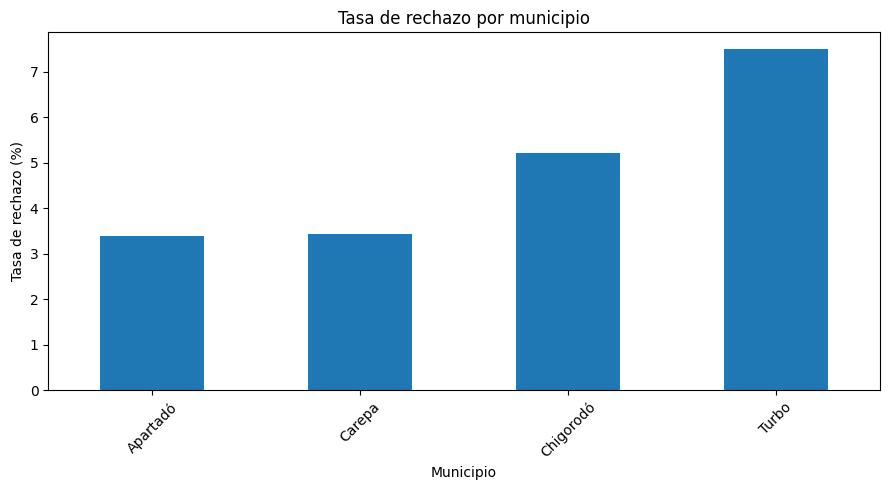

In [18]:
# Comparar la tasa de rechazo entre municipios
plt.figure(figsize=(9, 5))

analisis_municipio['tasa_rechazo'].sort_values().plot(kind='bar')

plt.title('Tasa de rechazo por municipio')
plt.xlabel('Municipio')
plt.ylabel('Tasa de rechazo (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

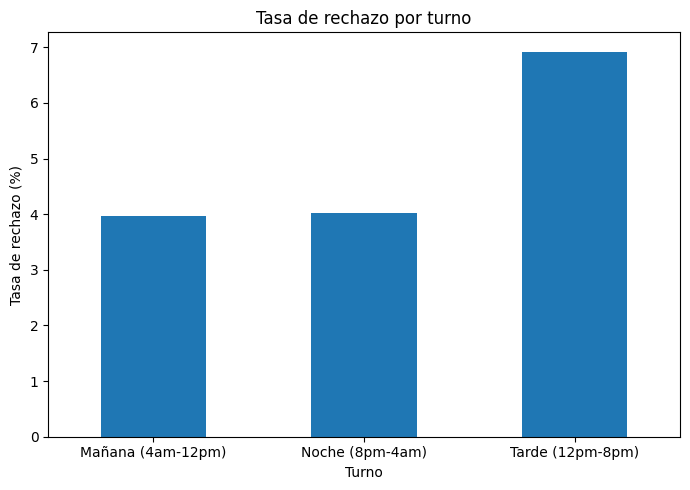

In [19]:
# Comparar la tasa de rechazo entre turnos
plt.figure(figsize=(7, 5))

analisis_turno['tasa_rechazo'].plot(kind='bar')

plt.title('Tasa de rechazo por turno')
plt.xlabel('Turno')
plt.ylabel('Tasa de rechazo (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

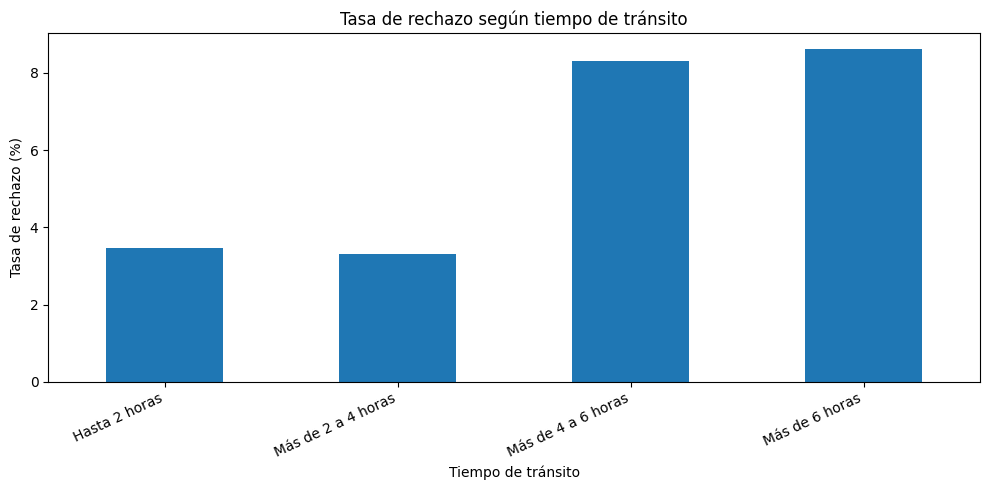

In [26]:
# Calcular la tasa de rechazo por rango de tránsito
rechazo_transito = df.groupby('rango_transito', observed=False).agg(
    cajas_enviadas=('cajas_enviadas', 'sum'),
    cajas_rechazadas=('cajas_rechazadas', 'sum')
)

rechazo_transito['tasa_rechazo'] = (
    rechazo_transito['cajas_rechazadas']
    / rechazo_transito['cajas_enviadas']
) * 100

# Graficar la tasa de rechazo
plt.figure(figsize=(10, 5))
rechazo_transito['tasa_rechazo'].plot(kind='bar')

plt.title('Tasa de rechazo según tiempo de tránsito')
plt.xlabel('Tiempo de tránsito')
plt.ylabel('Tasa de rechazo (%)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [25]:
# Exportar los datos limpios
df.to_csv('logistica_limpia.csv', index=False)

print("Archivo exportado correctamente.")
print(f"Total de registros: {len(df)}")
print(f"Horas de tránsito faltantes: {df['horas_transito'].isnull().sum()}")

Archivo exportado correctamente.
Total de registros: 1500
Horas de tránsito faltantes: 45


In [15]:
import os

print(os.path.exists('logistica_limpia.csv'))
print(os.listdir())

True
['limpieza_datos.ipynb', 'README.md', 'logistica_limpia.csv', 'generador_datos.py', 'Dashboard.pbix', '.git', 'logistica_banano_uraba.csv']
